In [3]:
%pip install shap
%pip install openpyxl
%pip install matplotlib seaborn xgboost scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl (9.3 MB)
  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
  Using cached xgboost-3.2.0-py3-none-win_amd64.whl (101.7 MB)
  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl (225 kB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached fonttools-4.67.0-cp311-cp311-win_amd64.whl (1.6 MB)
  Using cached kiwisolver-1.5.1-cp311-cp311-win_amd64.whl (70 kB)
  Using cached pillow-13.0.0-cp311-cp311-win_amd64.whl (7.3 MB)
  Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import shap
import warnings
warnings.filterwarnings("ignore")

sns.set(style='whitegrid')


c:\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
#  Load Dataset and Preprocess
df = pd.read_excel("LP_data_with_dates.xlsx", sheet_name="DATA")

# Drop timestamp (not useful for modeling)
df.drop(columns=["TIMESTAMP"], inplace=True)

# Rename columns to the API-friendly names expected by app.py / rf_features.pkl
df.rename(columns={
    "Launder (pH)": "Launder_pH",
    "Launder Total Hardness (ppm)": "Launder_Total_Hardness_ppm",
    "Launder Chloride (ppm)": "Launder_Chloride_ppm",
    "Launder TSS (ppm)": "Launder_TSS_ppm",
    "Overflow  pH": "Overflow_pH",
    "Overflow Total Hardness (ppm)": "Overflow_Total_Hardness_ppm",
    "Overflow chloride (ppm)": "Overflow_chloride_ppm",
    "Overflow TSS (ppm)": "Overflow_TSS_ppm",
    "GCP pH": "GCP_pH",
    "GCP Total Hardness (ppm)": "GCP_Total_Hardness_ppm",
    "GCP Chloride (ppm)": "GCP_Chloride_ppm",
}, inplace=True)

# Handle missing values
df.fillna(df.mean(), inplace=True)

# Quick view
df.head()


,BFG_CO,BFG_CO2,BFG_H2,BFG_PR_DOWNSTREAM_1,BFG_PR_DOWNSTREAM_2,BFG_PR_DWNSTRM_CTRL_VLV_POSI_1,BFG_PR_DWNSTRM_CTRL_VLV_POSI_2,BFG_PR_UPSTREAM_1,BFG_PR_UPSTRM_CTRL_VLV_POSI_1,BFG_PR_UPSTRM_CTRL_VLV_POSI_2,...,Launder_Chloride_ppm,Launder_TSS_ppm,Overflow_pH,Overflow_Total_Hardness_ppm,Overflow_chloride_ppm,Overflow_TSS_ppm,GCP_pH,GCP_Total_Hardness_ppm,GCP_Chloride_ppm,TOTAL_FLOW
0,25.698,25.309,4.076,0.082,0.081,11.089,0.480,0.101,91.765,99.105,...,1632,2756,7.14,790,1620,29,6.49,840.0,1622.0,829.834
1,25.023,24.823,4.246,0.081,0.080,30.535,0.485,0.098,93.773,99.131,...,1632,2756,7.14,790,1620,29,6.49,840.0,1622.0,824.656
2,25.455,25.230,4.112,0.077,0.077,10.098,0.484,0.098,78.053,92.389,...,1632,2756,7.14,790,1620,29,6.49,840.0,1622.0,825.956
3,25.722,25.342,3.867,0.081,0.080,11.707,0.473,0.101,77.035,97.010,...,1632,2756,7.14,790,1620,29,6.49,840.0,1622.0,829.753
4,25.485,25.145,4.130,0.081,0.080,21.175,0.484,0.101,83.199,99.614,...,1632,2756,7.14,790,1620,29,6.49,840.0,1622.0,825.290


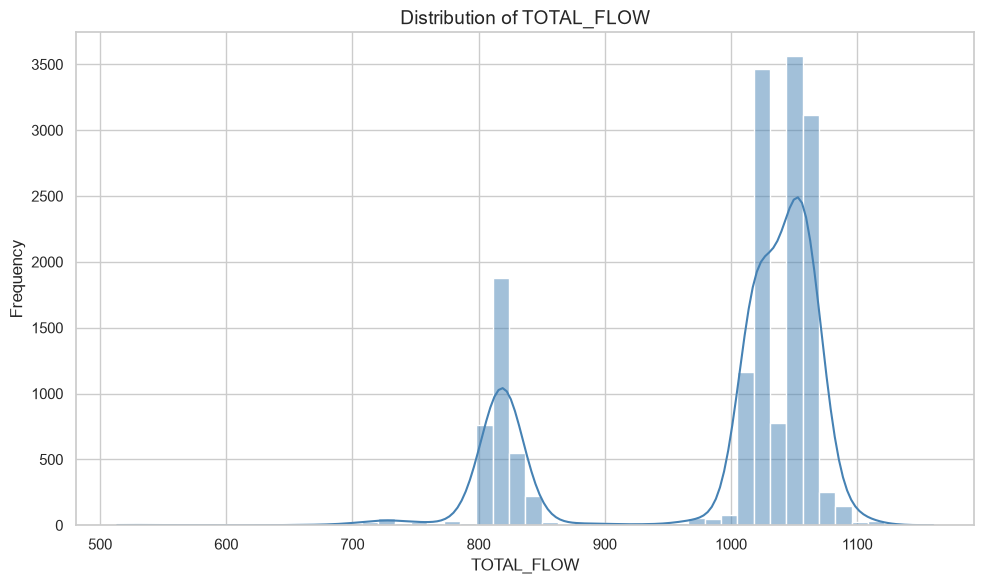

In [6]:
#Plot TOTAL_FLOW distribution
plt.figure(figsize=(10, 6))
sns.histplot(df["TOTAL_FLOW"], kde=True, bins=50, color="steelblue")
plt.title("Distribution of TOTAL_FLOW", fontsize=14)
plt.xlabel("TOTAL_FLOW")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [9]:
#Train-Test Split (80-20)
X = df.drop(columns=["TOTAL_FLOW"])
y = df["TOTAL_FLOW"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [10]:
# Train Models and Evaluate
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42, verbosity=0)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    results[name] = {
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "MAE": mean_absolute_error(y_test, preds),
        "R2": r2_score(y_test, preds),
        "model": model,
        "preds": preds
    }

pd.DataFrame({
    name: {
        "RMSE": r["RMSE"],
        "MAE": r["MAE"],
        "R²": r["R2"]
    }
    for name, r in results.items()
}).T


,RMSE,MAE,R²
Linear Regression,26.407401,15.010477,0.927933
Random Forest,7.044970,2.195996,0.994871
XGBoost,6.827051,2.388049,0.995183


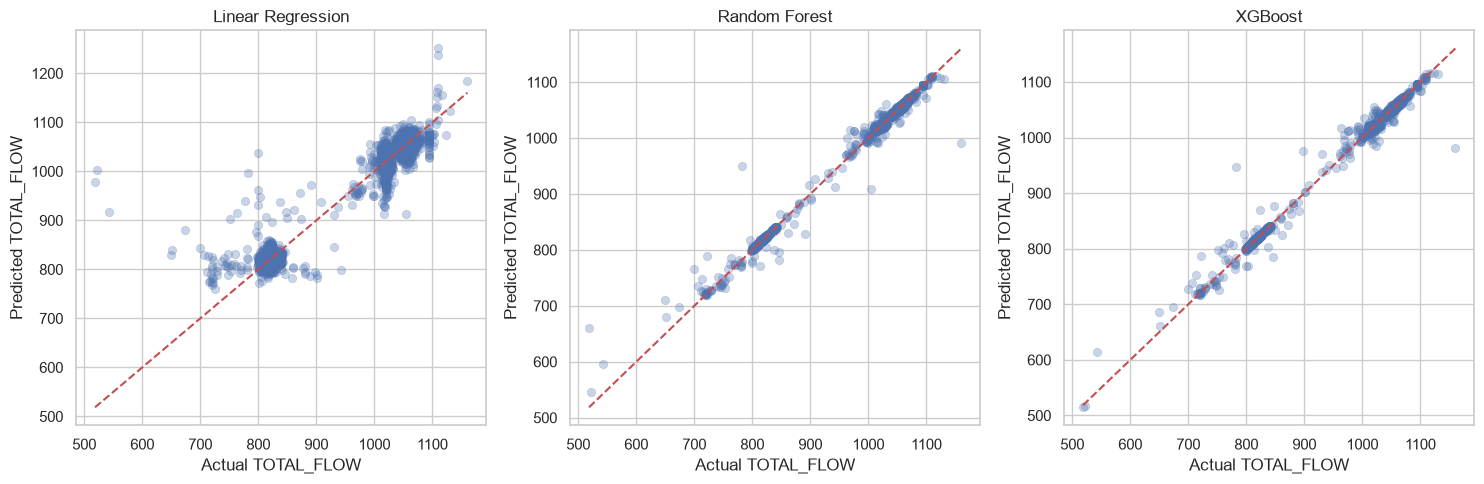

In [11]:
#Prediction Plots (Actual vs Predicted)
plt.figure(figsize=(15, 5))

for i, (name, r) in enumerate(results.items(), 1):
    plt.subplot(1, 3, i)
    sns.scatterplot(x=y_test, y=r["preds"], alpha=0.3, edgecolor=None)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual TOTAL_FLOW")
    plt.ylabel("Predicted TOTAL_FLOW")
    plt.title(name)

plt.tight_layout()
plt.show()


🔍 SHAP Interpretation for: Linear Regression


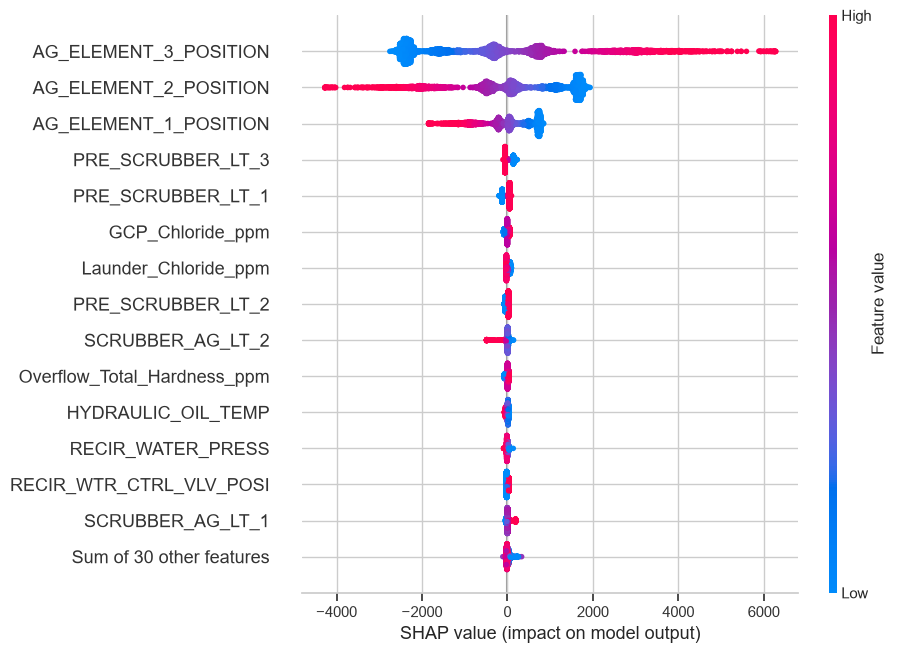

🔍 SHAP Interpretation for: Random Forest


100%|===================| 3291/3296 [07:22<00:00]        

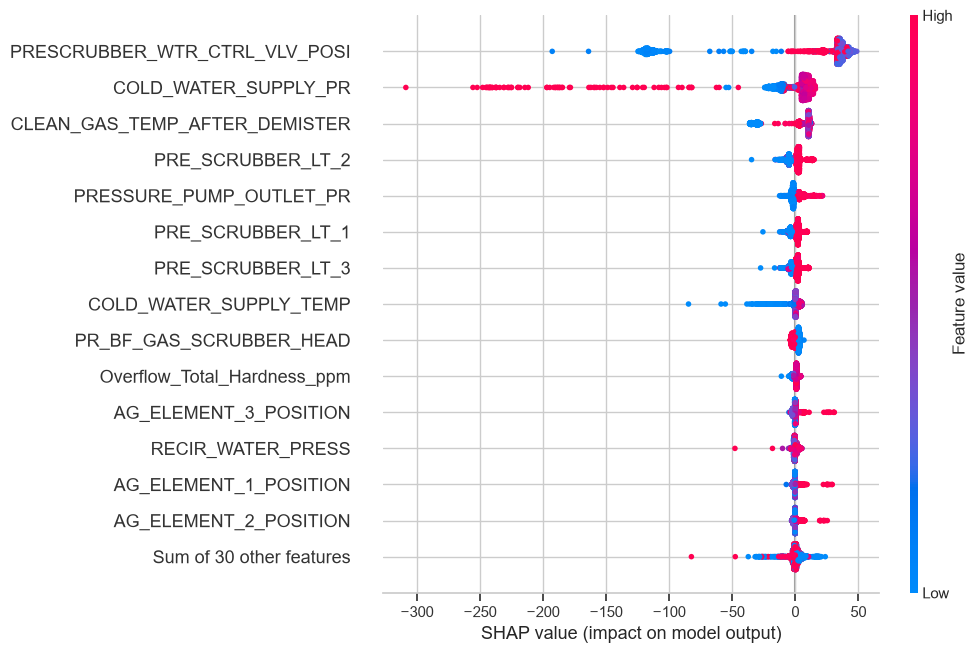

🔍 SHAP Interpretation for: XGBoost


 98%|===================| 3239/3296 [00:14<00:00]        

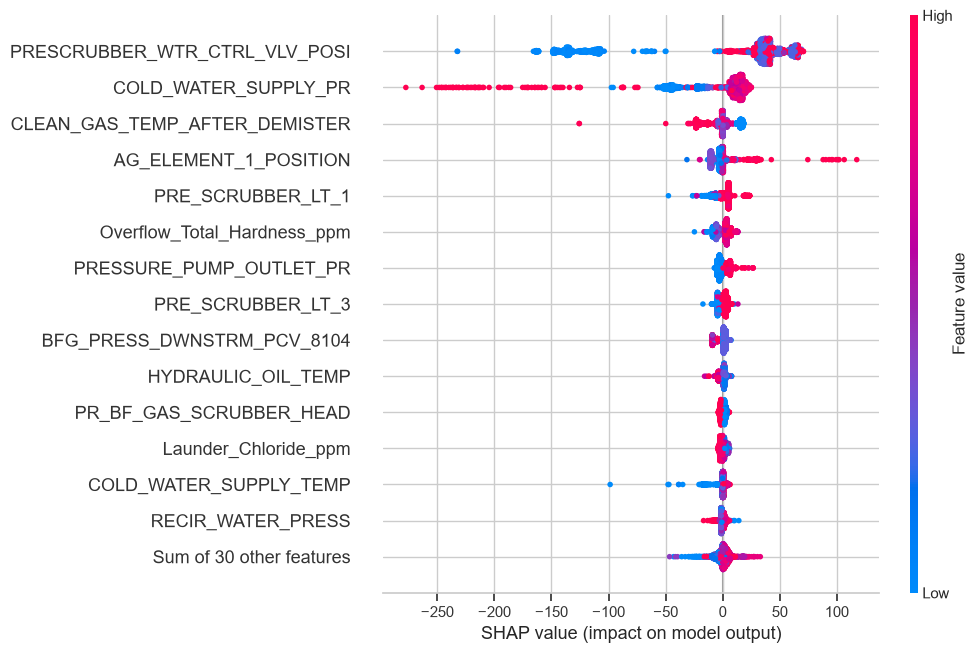

In [12]:
# SHAP summary plots for all three models
for name in ["Linear Regression", "Random Forest", "XGBoost"]:
    print(f"🔍 SHAP Interpretation for: {name}")

    model = results[name]["model"]

    # Use TreeExplainer for tree models, LinearExplainer for linear model
    if name == "Linear Regression":
        explainer = shap.Explainer(model, X_train)
    else:
        explainer = shap.Explainer(model, X_test)

    shap_values = explainer(X_test)

    # Show summary beeswarm plot
    shap.plots.beeswarm(shap_values, max_display=15)


In [13]:
import joblib

# Save each model from the results dictionary
joblib.dump(results["Linear Regression"]["model"], "lin_model.pkl")
joblib.dump(results["Random Forest"]["model"], "rf_model.pkl")
joblib.dump(results["XGBoost"]["model"], "xgb_model.pkl")

# Save the feature order used for training (loaded by app.py)
joblib.dump(list(X.columns), "rf_features.pkl")

print("✅ Models saved successfully!")


✅ Models saved successfully!
